``Aprendizado de Máquina e Profundo``

## Restauração de imagens com UNet

```OBS: Quando pedido, realize a operação na célula correspondente atribuindo o resultado na variável indicada. Não altere os nomes das variáveis utilizadas. Você pode utilizar celular adicionais para realizar testes, utilizando variaveis auxiliares para visualizar resultados intermediários.```

(Teste seu Notebook. Mantenha todas as saídas testadas. Celulas vazias nao serao avaliadas)

Neste exemplo, vamos gerar um modelo que identifica e remove o ruído de uma imagem de entrada, como na imagem de exemplo abaixo:

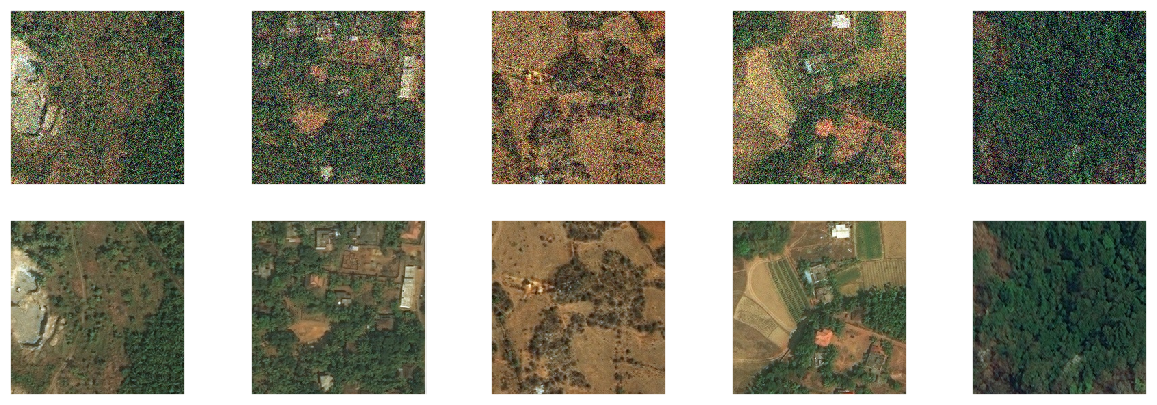

A imagem foi obtida do dataset [*Forest Aerial Images for Segmentation*](https://www.kaggle.com/datasets/quadeer15sh/augmented-forest-segmentation?resource=download)

Ilke Demir, et al. DeepGlobe 2018: A Challenge to Parse the Earth Through Satellite Images, CVPRW 2018.

O dataset foi inicialmente proposto para segmentação, por isso vamos processa-lo e adicionar as informações necessárias para podermos treinar nosso modelo.

No diagrama abaixo temos o fluxo utilizado para gerar os exemplos e treinar os modelos:

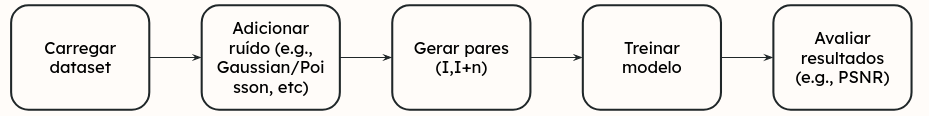

Primeiro, carregamos as imagens do dominio avaliado e adicionamos o ruído para que o modelo aprenda a identificar e remover a informação adicionada.

Nesse caso, a imagem original será a nossa label (target) e a imagem alterada será o exemplo passado para a rede.

Neste exemplo, vamos utilizar o [ruído gaussiano](https://pt.wikipedia.org/wiki/Ru%C3%ADdo_gaussiano).

O modelo que utilizaremos será a UNet, que deve receber as imagens com tamanho de entrada 256x256x3.
A especificação do modelo pode ser vista abaixo:

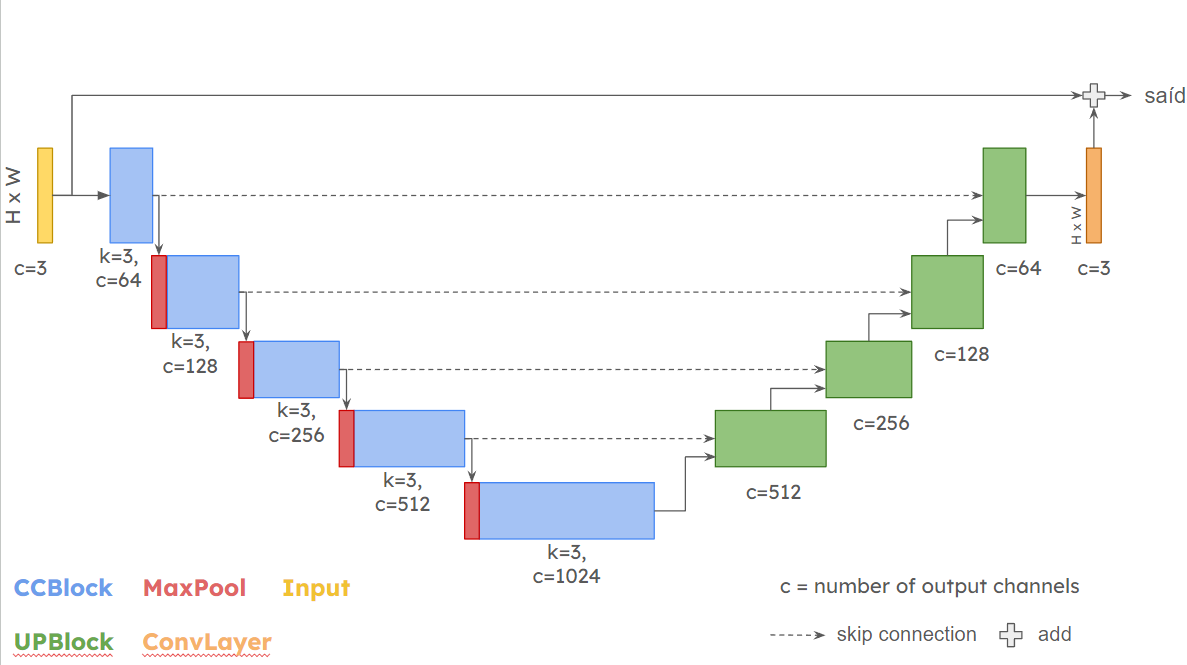

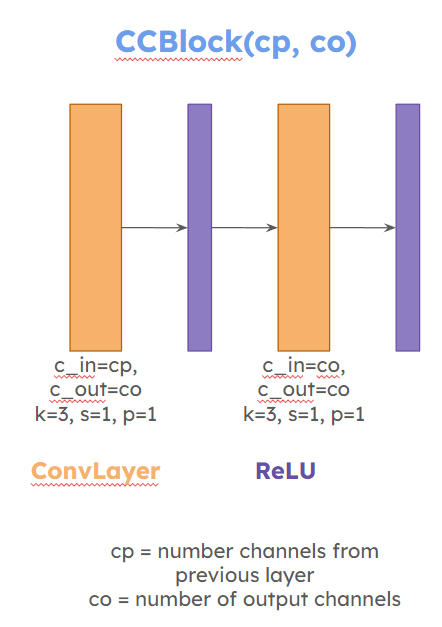

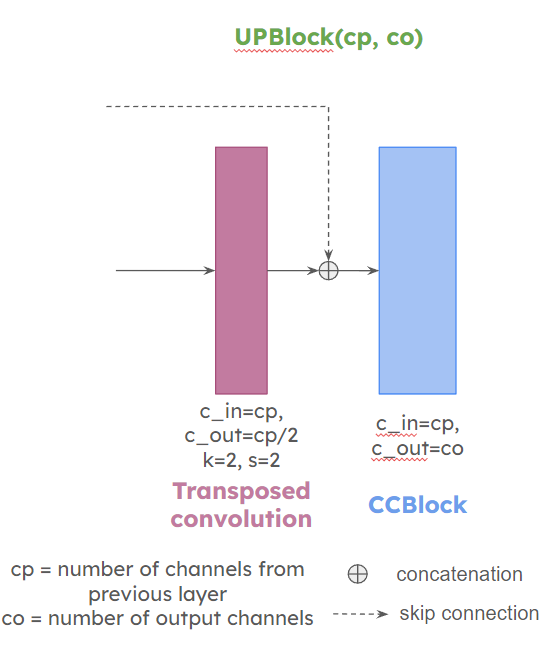

### 01 Importando bibliotecas e carregando o dataset

### Orientações de execução

O notebook foi executado com uma NVIDIA GeForce RTX 3050 Laptop GPU, usando batch de tamanho 1.

O treinamento utilizou Adam, learning rate de 0.0001, perda L1 e 10 épocas.

As imagens são escaladas pela divisão por 255, sem ajuste de estatísticas no conjunto de teste. As divisões utilizam random_state=42, e o melhor checkpoint é selecionado somente pela validação.

A avaliação final compara o erro L1 antes e depois da restauração. Os resultados e gráficos estão salvos neste notebook.

O dispositivo é selecionado automaticamente: GPU com CUDA quando disponível ou CPU. A execução em CPU pode ser mais demorada.


In [ ]:
# Dependências: torch torchvision scikit-learn torchsummary matplotlib seaborn
# opencv-python Pillow albumentations numpy pandas tqdm gdown
import random
import torch
from torchvision import transforms, datasets, models
from torch import nn, optim
from torch.utils import data
from sklearn.model_selection import train_test_split
from torchsummary import summary
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import cv2
from PIL import Image
import albumentations as A
import zipfile
import os
import glob
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
import sys
REQUIRE_GPU_TRAINING = False # False permite treino deliberado em CPU.
print("Python do kernel:", sys.executable)
print("CUDA da instalação:", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("AVISO: CUDA indisponível. Instale PyTorch com CUDA no ambiente deste kernel antes de treinar.")


c:\Users\edson\Downloads\Atividade Extra\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cu126 | CUDA: True
Python do kernel: c:\Users\edson\Downloads\Atividade Extra\.venv\Scripts\python.exe
CUDA da instalação: 12.6
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# Download e extração compatíveis com Windows e Colab.
import gdown
archive = "kaggle_forest_segmentation.zip"
metadata_file = "./kaggle_forest_segmentation/Forest Segmented/Forest Segmented/meta_data.csv"
if not os.path.isfile(metadata_file):
    if not os.path.isfile(archive):
        gdown.download(id="19nkkxpK8LN7fk9VPCdR1heatXhQKNWtO", output=archive, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise RuntimeError("Download inválido: verifique o acesso ao dataset do enunciado.")
    with zipfile.ZipFile(archive) as z:
        z.extractall(".")
if not os.path.isfile(metadata_file):
    raise FileNotFoundError("Confira a estrutura extraída e o caminho do meta_data.csv.")
print("Dataset disponível:", metadata_file)

Downloading...
From (original): https://drive.google.com/uc?id=19nkkxpK8LN7fk9VPCdR1heatXhQKNWtO
From (redirected): https://drive.google.com/uc?id=19nkkxpK8LN7fk9VPCdR1heatXhQKNWtO&confirm=t&uuid=1c7320d4-5853-43d7-8da8-9749ed4917db
To: c:\Users\edson\Downloads\Atividade Extra\kaggle_forest_segmentation.zip
100%|██████████| 182M/182M [00:22<00:00, 8.16MB/s] 


Dataset disponível: ./kaggle_forest_segmentation/Forest Segmented/Forest Segmented/meta_data.csv


In [3]:
class AverageMeter:
    """Computes and stores the average and current value"""
    # fonte: https://kaiyangzhou.github.io/deep-person-reid/_modules/torchreid/utils/avgmeter.html#AverageMeter
    def __init__(self):
        self.reset()

    def reset(self):
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

### 01 - Gerando o dataset

#### 01.1 Defina a função que adiciona ruído normal na imagem
- A função receberá a imagem (np) com pixels entre 0 e 1, e o valor sigma
- Adicione o ruído gaussiano ([np.random.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html)) com média 0 e std sigma/255 (lembre de checar se os valores ultrapassam o range 0-1, use o [np.clip](https://numpy.org/doc/stable/reference/generated/numpy.clip.html) para ajustar os valores)

In [4]:
def add_noise(image, sigma) -> np.array:
    if sigma < 0:
        raise ValueError("sigma deve ser não negativo.")
    image = np.asarray(image, dtype=np.float32)
    noise = np.random.normal(0.0, sigma / 255.0, size=image.shape)
    return np.clip(image + noise, 0.0, 1.0).astype(np.float32)

In [5]:
metadata_file = "./kaggle_forest_segmentation/Forest Segmented/Forest Segmented/meta_data.csv"
metadata = pd.read_csv(metadata_file)
metadata.head()

,image,mask
0,10452_sat_08.jpg,10452_mask_08.jpg
1,10452_sat_18.jpg,10452_mask_18.jpg
2,111335_sat_00.jpg,111335_mask_00.jpg
3,111335_sat_01.jpg,111335_mask_01.jpg
4,111335_sat_02.jpg,111335_mask_02.jpg


In [6]:
DIRECTORY = "./kaggle_forest_segmentation/Forest Segmented/Forest Segmented/"
SIGMA     = 50

if not os.path.exists(os.path.join(DIRECTORY, "noisy")):
    os.mkdir(os.path.join(DIRECTORY, "noisy"))

np.random.seed(SEED)
noisy_imgs = []
for i in tqdm(range(len(metadata))):
    path = os.path.join(DIRECTORY, "images", metadata.iloc[i]["image"])
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(path)
    img = img.astype("float32") / 255
    noisy = add_noise(img, SIGMA)
    noisy = (noisy * 255).astype('uint8')
    noisy_path = os.path.join(DIRECTORY, "noisy", metadata.iloc[i]["image"].replace("sat", "noisy"))
    if cv2.imwrite(noisy_path, noisy):
        noisy_imgs.append(metadata.iloc[i]["image"].replace("sat", "noisy"))
    else:
        noisy_imgs.append(np.nan)

metadata["noisy"] = noisy_imgs

# Estrutura da pasta
"""
kaggle_forest_segmentation
  Forest Segmented/
    Forest Segmented/
      images/
      masks/
      noisy/
      meta_data.csv
"""

100%|██████████| 5108/5108 [00:51<00:00, 99.84it/s] 


'\nkaggle_forest_segmentation\n  Forest Segmented/\n    Forest Segmented/\n      images/\n      masks/\n      noisy/\n      meta_data.csv\n'

In [7]:
metadata.head()

,image,mask,noisy
0,10452_sat_08.jpg,10452_mask_08.jpg,10452_noisy_08.jpg
1,10452_sat_18.jpg,10452_mask_18.jpg,10452_noisy_18.jpg
2,111335_sat_00.jpg,111335_mask_00.jpg,111335_noisy_00.jpg
3,111335_sat_01.jpg,111335_mask_01.jpg,111335_noisy_01.jpg
4,111335_sat_02.jpg,111335_mask_02.jpg,111335_noisy_02.jpg


In [8]:
if metadata["noisy"].isna().any():
    raise RuntimeError("Há imagens com ruído que não foram salvas corretamente.")
train_val_paths, test_paths = train_test_split(metadata, test_size=0.2, random_state=42)
train_paths, val_paths = train_test_split(train_val_paths, test_size=0.15, random_state=42)
assert set(train_paths.index).isdisjoint(val_paths.index)
assert set(train_paths.index).isdisjoint(test_paths.index)
assert set(val_paths.index).isdisjoint(test_paths.index)

In [9]:
# os exemplos estarão dividos e serão acessados atraves do dataframe carregado
train_paths.shape[0], val_paths.shape[0], test_paths.shape[0]

(3473, 613, 1022)

#### 01.2 Crie a classe de dataset que vamos utilizar para o treinamento
- defina as funções `__init__`, `__len__`, e `__getitem__`
- retorne a imagem original e a imagem com ruído
- Antes de retornar, transforme as imagens para torch.Tensor
- Lembre de ajustar as dimensões antes de retornar (torch=C,H,W, numpy/opencv=H,W,C)
- cheque o conteudo de train_paths, val_paths e test_paths, você deve ter acesso as imagens originais e com ruído a partir dessas variaveis (elas devem ser passadas no `__init__`)

In [10]:
class ForestImages(data.Dataset):
    def __init__(self, paths):
        self.paths = paths.reset_index(drop=True).copy()
        self.directory = DIRECTORY

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        row = self.paths.iloc[index]
        tensors = []
        # Entrada ruidosa primeiro; imagem limpa como alvo.
        for folder, column in [("noisy", "noisy"), ("images", "image")]:
            path = os.path.join(self.directory, folder, row[column])
            image = cv2.imread(path, cv2.IMREAD_COLOR)
            if image is None:
                raise FileNotFoundError(path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            if image.shape[:2] != (256, 256):
                image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)
            image = image.astype(np.float32) / 255.0
            tensors.append(torch.from_numpy(image.transpose(2, 0, 1).copy()))
        return tensors[0], tensors[1]

#### 01.3 Crie as variaveis do dataset de treino, validação e teste passando os respectivos caminhos e gere os dataloaders que serão usados no treino

In [11]:
train_ds = ForestImages(train_paths)
valid_ds = ForestImages(val_paths)
test_ds = ForestImages(test_paths)

BATCH_SIZE = 1  # Conservador para os 4 GB da RTX 3050; arquitetura preservada.
train_dl = data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available(), drop_last=False,
    generator=torch.Generator().manual_seed(42))
valid_dl = data.DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available(), drop_last=False)
test_dl = data.DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available(), drop_last=False)
instances, targets = next(iter(train_dl))
print(instances.shape, targets.shape)
assert instances.dtype == targets.dtype == torch.float32
assert instances.shape[1:] == (3, 256, 256)

torch.Size([1, 3, 256, 256]) torch.Size([1, 3, 256, 256])


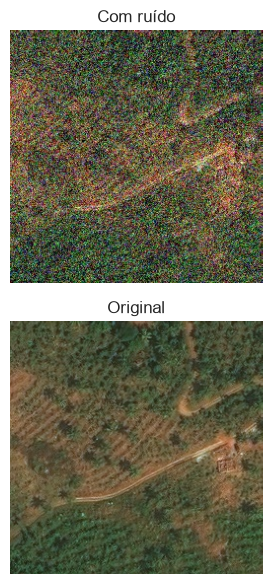

In [12]:
w = min(5, len(instances))
fig, ax = plt.subplots(2, w, figsize=(4*w, 6), squeeze=False)
for j in range(w):
    ax[0, j].imshow(instances[j].permute(1, 2, 0).numpy())
    ax[0, j].set_title("Com ruído")
    ax[1, j].imshow(targets[j].permute(1, 2, 0).numpy())
    ax[1, j].set_title("Original")
    ax[0, j].axis("off")
    ax[1, j].axis("off")
plt.tight_layout()
plt.show()

### 02 - Defina o modelo

#### 02.1 - Defina o bloco "CCBlock" como uma classe que herda de nn.Module (implemente o `__init__` e `forward`)
#### 02.2 - Defina o bloco "UpBlock"
- Voce pode utilizar o CCBlock internamente
- Trate no forward o uso da entrada e do skip connection
- Para juntar a entrada da camada com a entrada do skip use a função `torch.cat`

#### 02.3 - Construa o modelo utilizando as classes CCBlock e UpBlock
- Utilize outros módulos quando necessário (e.g., max pooling, convlayer)

#### 02.4 - Crie uma instancia para o modelo e passe para o device do ambiente
#### 02.5 - Imprima o modelo com o summary

In [13]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Dispositivo selecionado:", device)


Dispositivo selecionado: cuda:0


In [14]:
class CCBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1),
            nn.ReLU())

    def forward(self, x):
        return self.layers(x)

In [15]:
class UpBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = CCBlock(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = nn.functional.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat((x, skip), dim=1))

In [16]:
class Unet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.enc1 = CCBlock(in_channels, 64)
        self.enc2 = CCBlock(64, 128)
        self.enc3 = CCBlock(128, 256)
        self.enc4 = CCBlock(256, 512)
        self.center = CCBlock(512, 1024)
        self.pool = nn.MaxPool2d(2)
        self.up4 = UpBlock(1024, 512)
        self.up3 = UpBlock(512, 256)
        self.up2 = UpBlock(256, 128)
        self.up1 = UpBlock(128, 64)
        self.output = nn.Conv2d(64, out_channels, kernel_size=1)
        self.residual = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        h = self.center(self.pool(e4))
        h = self.up4(h, e4)
        h = self.up3(h, e3)
        h = self.up2(h, e2)
        h = self.up1(h, e1)
        # Soma residual indicada no diagrama: a rede aprende uma correção.
        return self.output(h) + self.residual(x)

In [17]:
# Resumo sem manter ativações para backward nem uma segunda rede na GPU.
_summary_model = Unet().to(device)
with torch.no_grad():
    summary(_summary_model, (3, 256, 256), 1, device.type)
del _summary_model
if device.type == "cuda":
    torch.cuda.empty_cache()


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [1, 64, 256, 256]           1,792
              ReLU-2          [1, 64, 256, 256]               0
            Conv2d-3          [1, 64, 256, 256]          36,928
              ReLU-4          [1, 64, 256, 256]               0
           CCBlock-5          [1, 64, 256, 256]               0
         MaxPool2d-6          [1, 64, 128, 128]               0
            Conv2d-7         [1, 128, 128, 128]          73,856
              ReLU-8         [1, 128, 128, 128]               0
            Conv2d-9         [1, 128, 128, 128]         147,584
             ReLU-10         [1, 128, 128, 128]               0
          CCBlock-11         [1, 128, 128, 128]               0
        MaxPool2d-12           [1, 128, 64, 64]               0
           Conv2d-13           [1, 256, 64, 64]         295,168
             ReLU-14           [1, 256,

In [18]:
model = Unet().to(device)
print("Modelo em:", next(model.parameters()).device)


Modelo em: cuda:0


### Faça o treinamento

#### 03.1 Implemente o passo de treinamento
- Ative o modo de treino
- Faça o loop para iterar sob os batches
- Passe os exemplos e labels para o device do ambiente
- Realize os passos de treino (predição, loss, backpropagation)
- Retorne a média do loss

#### 03.2 Implemente o passo de validação
- Ative o modo de avaliação
- Desative os gradientes
- Faça o loop para iterar sob os batches
- Realize a avaliação (predição, loss)
- Retorne a média do loss

In [19]:
def train_step(model, loader, loss_fn, optimizer, device) -> float:
    model.to(device)
    model.train()
    total_loss, count = 0.0, 0
    for instances, targets in tqdm(loader, desc="Treino", leave=False):
        instances, targets = instances.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad()
        predictions = model(instances)
        loss = loss_fn(predictions, targets)
        loss.backward()
        optimizer.step()
        n = instances.size(0)
        total_loss += loss.item() * n
        count += n
    if count == 0:
        raise ValueError("Loader de treino vazio.")
    return float(total_loss / count)


def validation_step(model, loader, loss_fn, device) -> float:
    model.to(device)
    model.eval()
    total_loss, count = 0.0, 0
    with torch.no_grad():
        for instances, targets in tqdm(loader, desc="Validação", leave=False):
            instances, targets = instances.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            loss = loss_fn(model(instances), targets)
            n = instances.size(0)
            total_loss += loss.item() * n
            count += n
    if count == 0:
        raise ValueError("Loader de validação vazio.")
    return float(total_loss / count)

#### 03.4 Defina a função para executar o treino
- Defina o otimizador
- Defina a função de loss (use o loss L1)
- Defina o numero de epocas
- Itere sob as épocas executando o treinamento e validação em cada passo
- Salve (em lista) o loss de treino e validação em cada passo (imprima também o resultado em cada passo)
- Escolha o otimizador, o learning rate e o número de épocas para que o modelo aprenda corretamente (avalie os valores de loss de treino e validação para checar o resultado, e.g., overfitting ou underfitting)

In [20]:
train_losses = list()
valid_losses = list()

In [21]:
def train_model():
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = nn.L1Loss()
    epochs = 10  # Configuração inicial; avaliar pelas curvas de validação.
    train_losses.clear()
    valid_losses.clear()
    best_loss = float("inf")
    for epoch in range(epochs):
        train_loss = train_step(model, train_dl, loss_fn, optimizer, device)
        valid_loss = validation_step(model, valid_dl, loss_fn, device)
        train_losses.append(train_loss)
        valid_losses.append(valid_loss)
        print(f"Época {epoch+1}/{epochs} | treino: {train_loss:.6f} | validação: {valid_loss:.6f}")
        if valid_loss < best_loss:
            best_loss = valid_loss
            torch.save(model.state_dict(), "unet_melhor_validacao.pth")
    # Seleção exclusivamente pela validação, sem consultar o teste.
    model.load_state_dict(torch.load("unet_melhor_validacao.pth", map_location=device, weights_only=True))

In [22]:
if REQUIRE_GPU_TRAINING and device.type != "cuda":
    raise RuntimeError(
        "Treinamento não iniciado: GPU indisponível. Instale PyTorch com CUDA "
        "no Python indicado na primeira célula e reinicie o kernel. "
        "Para optar por CPU, defina REQUIRE_GPU_TRAINING = False.")
print("Iniciando treinamento em:", next(model.parameters()).device)
train_model()


Iniciando treinamento em: cuda:0


Época 1/10 | treino: 0.035890 | validação: 0.031908


Época 2/10 | treino: 0.030824 | validação: 0.030437


Época 3/10 | treino: 0.030327 | validação: 0.030146


Época 4/10 | treino: 0.030112 | validação: 0.030093


Época 5/10 | treino: 0.029933 | validação: 0.029769


Época 6/10 | treino: 0.029827 | validação: 0.029802


Época 7/10 | treino: 0.029741 | validação: 0.029690


Época 8/10 | treino: 0.029640 | validação: 0.030137


Época 9/10 | treino: 0.029614 | validação: 0.029605


Época 10/10 | treino: 0.029522 | validação: 0.029570


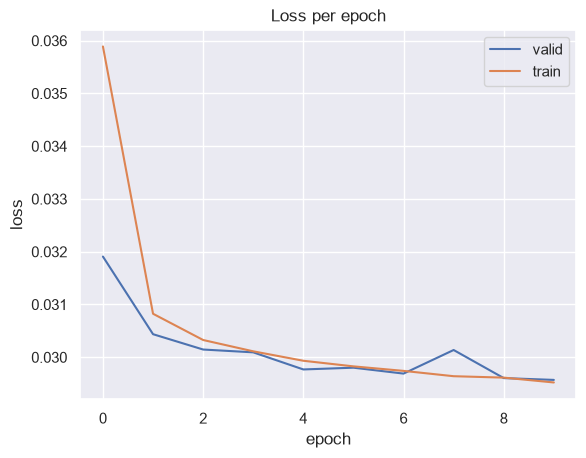

In [23]:
def plot_loss(loss_train, loss_valid):
  plt.plot(loss_valid, label='valid')
  plt.plot(loss_train, label='train')
  plt.title('Loss per epoch');
  plt.ylabel('loss');
  plt.xlabel('epoch')
  plt.legend()
  plt.show()

plot_loss(train_losses, valid_losses)

### 03.5 Salve o modelo

In [24]:
torch.save(model.state_dict(), "unet_restauracao.pth")
pd.DataFrame({"train_loss": train_losses, "valid_loss": valid_losses}).to_csv("historico_unet.csv", index=False)
print("Modelo salvo em unet_restauracao.pth; histórico salvo em historico_unet.csv.")

Modelo salvo em unet_restauracao.pth; histórico salvo em historico_unet.csv.


### 04 - Teste se o seu modelo está removendo ruídos corretamente

Teste final: 100%|██████████| 1022/1022 [00:29<00:00, 34.65it/s]


L1 antes da restauração: 0.103727
L1 após a restauração:   0.029693
Houve redução do erro médio: True


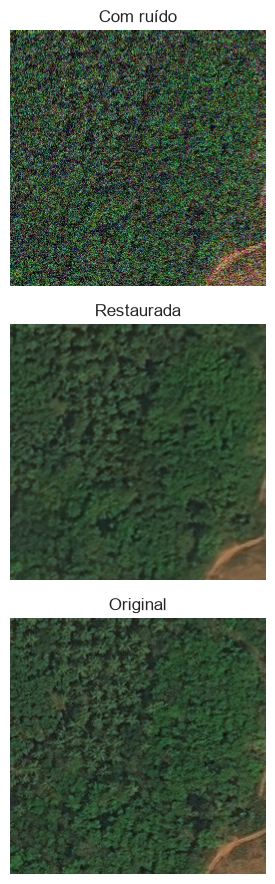

In [25]:
# Avaliação final: não ajustar configurações com base nestes resultados.
model.eval()
noisy_error, restored_error, count = 0.0, 0.0, 0
examples = None
with torch.no_grad():
    for instances, targets in tqdm(test_dl, desc="Teste final"):
        instances, targets = instances.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        predictions = model(instances)
        n = instances.size(0)
        noisy_error += nn.functional.l1_loss(instances, targets).item() * n
        restored_error += nn.functional.l1_loss(predictions, targets).item() * n
        count += n
        if examples is None:
            examples = (instances.cpu(), targets.cpu(), predictions.cpu())
if count == 0:
    raise ValueError("Loader de teste vazio.")
print(f"L1 antes da restauração: {noisy_error/count:.6f}")
print(f"L1 após a restauração:   {restored_error/count:.6f}")
print("Houve redução do erro médio:", restored_error < noisy_error)
instances, targets, predictions = examples
w = min(5, len(instances))
fig, ax = plt.subplots(3, w, figsize=(4*w, 9), squeeze=False)
for j in range(w):
    for row, (batch, title) in enumerate([(instances, "Com ruído"), (predictions, "Restaurada"), (targets, "Original")]):
        # Limitar valores apenas para exibição; métricas usam saída original.
        ax[row, j].imshow(batch[j].permute(1, 2, 0).clamp(0, 1).numpy())
        ax[row, j].set_title(title)
        ax[row, j].axis("off")
plt.tight_layout()
plt.show()